In [ ]:
# bismillahirrahmanirrahim

# kütüphanelerin içe aktarılması
# temel kütüphaneler

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Makine Öğrenmesi
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier, NeighborhoodComponentsAnalysis, LocalOutlierFactor, 
from sklearn.decomposition import PCA

# uyarılar
import warnings
warnings.filterwarnings("ignore")

In [71]:
data = pd.read_csv("kanser.csv")
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [72]:
# gereksiz özellikleri çıkar
data.drop(columns=["id", "Unnamed: 32"], inplace=True, errors="ignore")

In [73]:
# verinin içerisinde bulunan hastalık tanımı özelliğinin ismini değiştir
data = data.rename(columns= {"diagnosis": "hedef"})

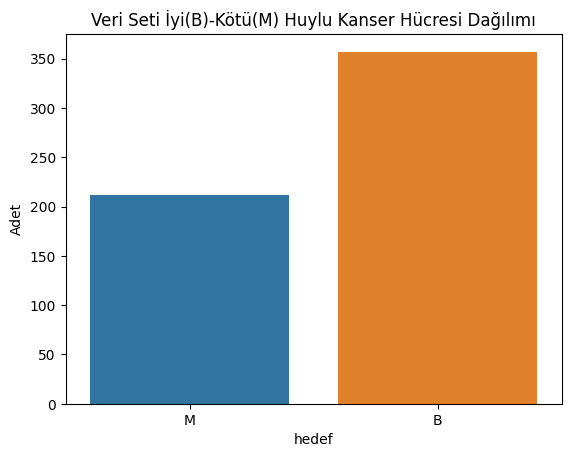

hedef
B    357
M    212
Name: count, dtype: int64


In [76]:
plt.figure()
sns.countplot(data=data, x="hedef", hue="hedef")
plt.ylabel("Adet")
plt.title("Veri Seti İyi(B)-Kötü(M) Huylu Kanser Hücresi Dağılımı")
plt.show()
print(data.hedef.value_counts())

In [77]:
# verinin içerisinde hedef etiketinin altında bulan verilerin tipini ve içeriğini değiştiriyoruz 
# "M" => 1, "B" => 0
data["hedef"] = [1 if i.strip() == "M" else 0 for i in data.hedef]
data.head(3)

,hedef,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [46]:
# verinin uzunluğu
print("Verinin uzunluğu: ", len(data))

Verinin uzunluğu:  569


In [47]:
# verinin şekli 
print("verinin şekli: ", data.shape)

verinin şekli:  (569, 31)


In [39]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hedef                    569 non-null    int64  
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [78]:
# verinin temel istatistiksel özellikleri
data.describe()

,hedef,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,0.372583,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,0.483918,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,0.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,0.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,0.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,1.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,1.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


<Figure size 1200x800 with 0 Axes>

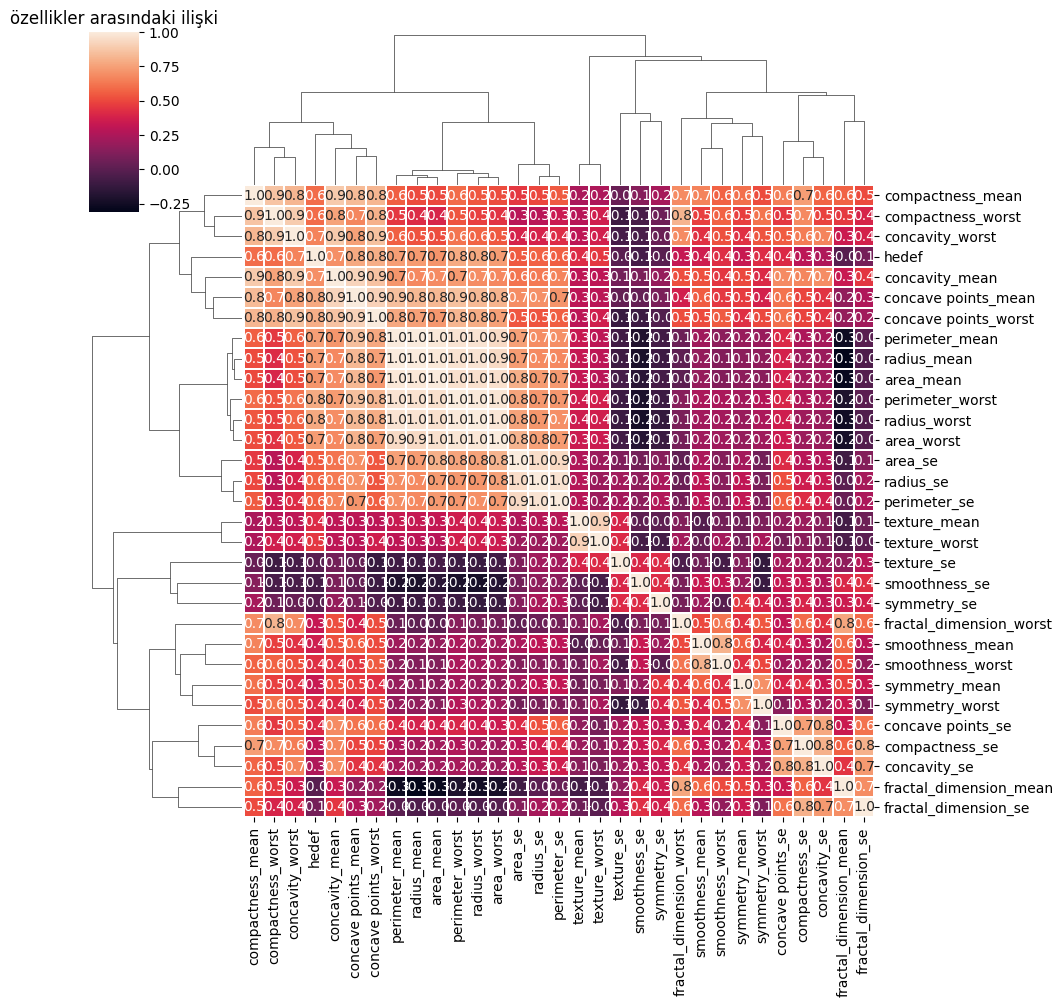

In [80]:
# verinin içerisinde bulunan değerlerin arasındaki ilişkiye bakalım
corr_matrix = data.corr()
plt.figure(figsize=(12,8))
sns.clustermap(corr_matrix, annot= True, fmt=".1f", linewidths=.01)
plt.title("özellikler arasındaki ilişki")
plt.show()

<Figure size 640x480 with 0 Axes>

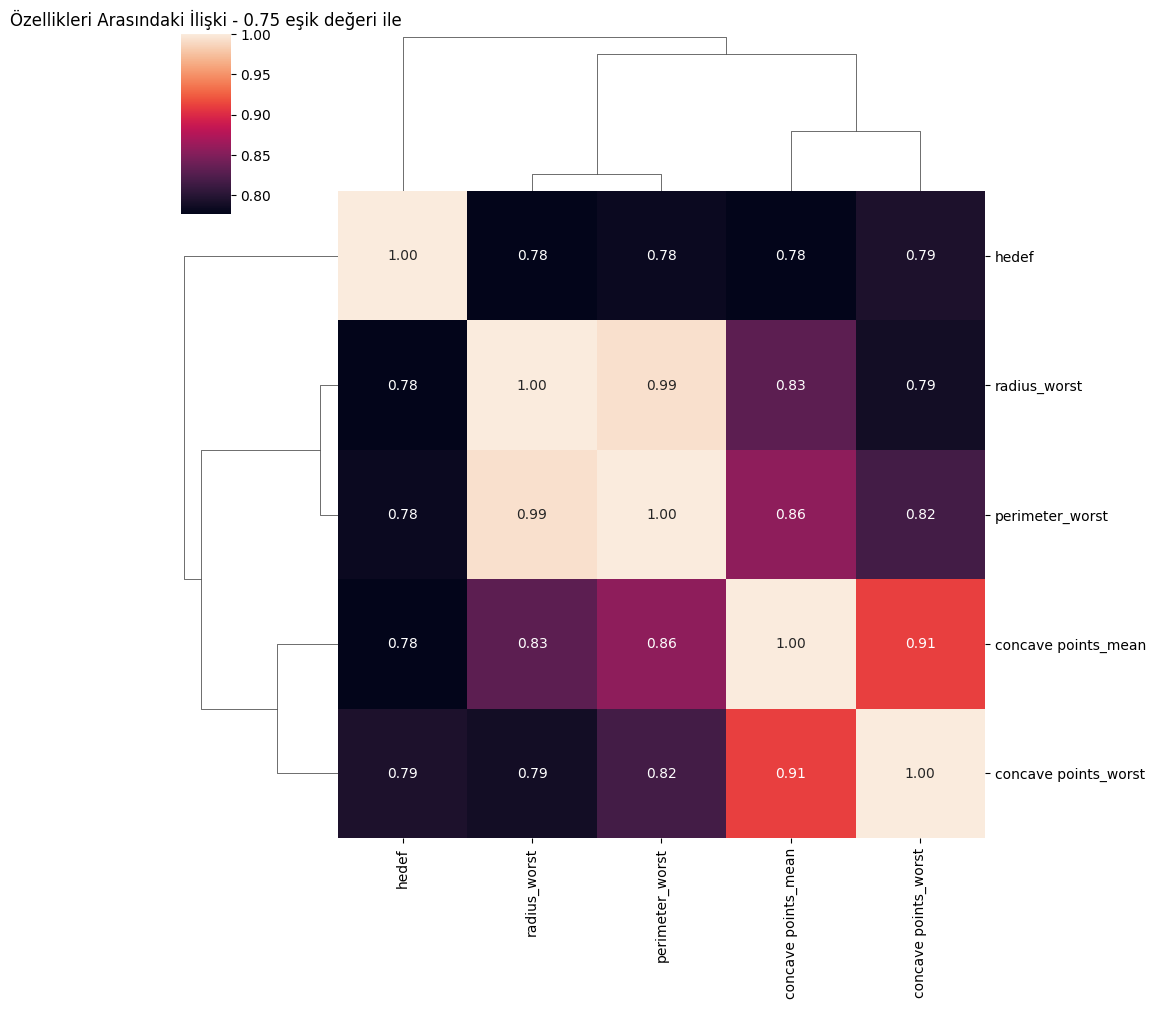

In [51]:
# hedef ile arasındaki ilişki artı/eksi 0.75 den büyük olanlara ayrıca göz atalım
threshold = 0.75
filtre = np.abs(corr_matrix["hedef"]) > threshold
corr_features = corr_matrix.columns[filtre].tolist()
plt.figure()
sns.clustermap(data[corr_features].corr(), annot=True, fmt=".2f")
plt.title("Özellikleri Arasındaki İlişki - 0.75 eşik değeri ile")
plt.show()


<Figure size 640x480 with 0 Axes>

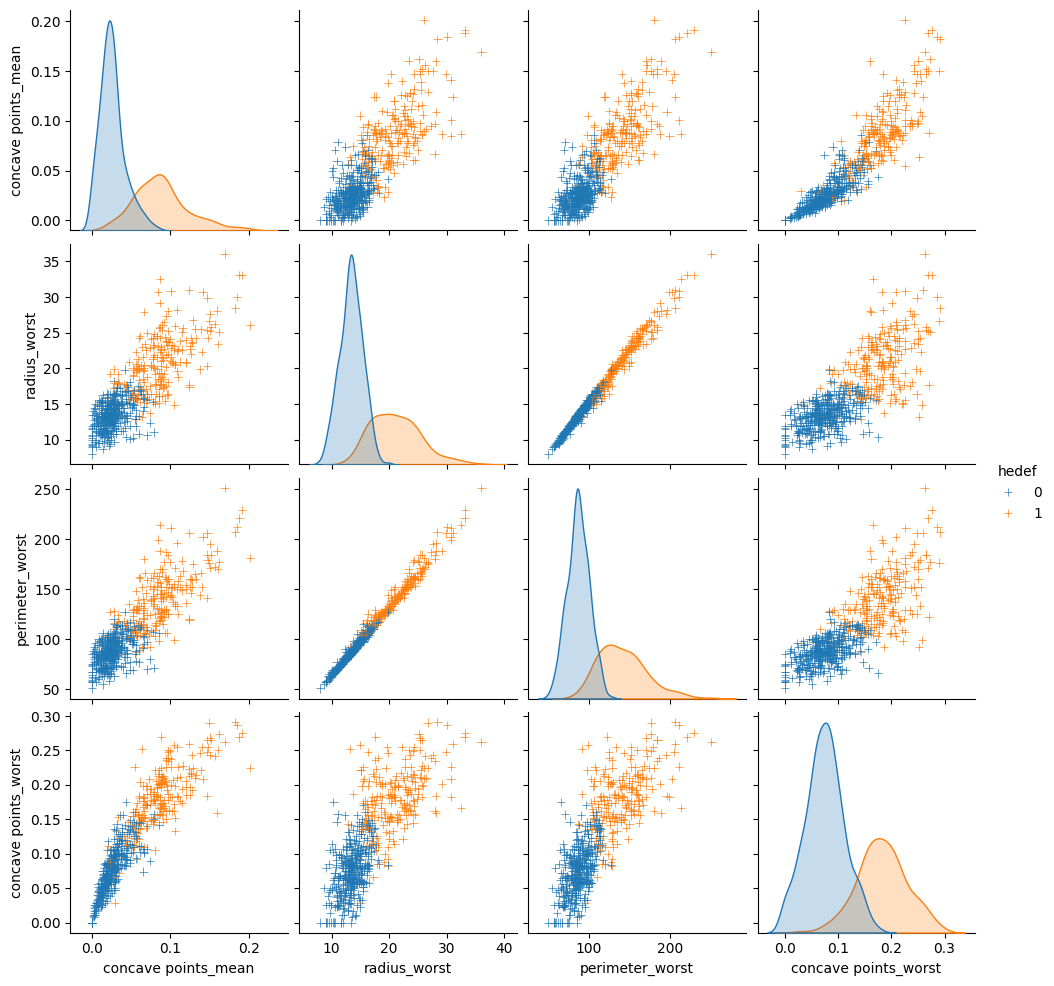

In [81]:
# hedef ile ilişkili özelliklerin saçılımına bakalım
plt.figure()
sns.pairplot(data[corr_features], diag_kind= "kde", markers="+", hue="hedef")
plt.show()

In [83]:
# veriyi x (bağımsız değişken) ve y (bağımlı değişken) olmak üzere ikiye ayıralım
y = data.hedef
x = data.drop(["hedef"], axis=1)
columns = x.columns.tolist()

In [84]:
# yerel aykırı faktör yöntemi
clf = LocalOutlierFactor()

# yerel aykırı faktör yöntemi uygulayalım
y_pred = clf.fit_predict(x)

#skora bakalım
X_score = clf.negative_outlier_factor_

X_score

array([-1.42244008, -1.06678249, -0.97894764, -1.59693295, -1.06993589,
       -1.773071  , -1.01568723, -1.25174625, -1.38051485, -1.64435685,
       -0.99760184, -1.06178607, -1.12949091, -1.25844429, -0.96863713,
       -1.09335084, -1.13938097, -1.06049329, -1.41067136, -0.97224755,
       -0.98172267, -1.01796076, -1.00120872, -1.55647306, -1.76479918,
       -1.14444971, -1.18253923, -1.05669361, -1.1171278 , -0.96612603,
       -0.98190689, -1.99760079, -1.00701649, -1.00581116, -1.01466535,
       -0.98769018, -0.98362673, -1.39411328, -2.2334333 , -1.09045555,
       -1.14776543, -1.31502499, -0.98035055, -1.4174209 , -1.28342864,
       -0.98156833, -1.32235455, -1.32568003, -1.09322188, -0.97065701,
       -0.97278561, -1.05918996, -0.97370459, -1.02944   , -1.03748568,
       -1.00072293, -1.24017071, -1.05450437, -0.99159205, -1.09401411,
       -0.98594633, -1.09659782, -1.08187925, -1.00799336, -1.59848383,
       -1.05245105, -1.02666387, -0.97040029, -1.01252311, -1.06

In [67]:
# skoru bir veri çerçevesi yapıp içerisine ekledim
outlier_score = pd.DataFrame()
outlier_score["score"] = X_score
outlier_score.shape

(569, 1)

In [109]:
# belirli bir eşik değerine göre aykırı değerleri bulalım 
threshold = -2.2
filtre = outlier_score["score"] < threshold
outlier_index = outlier_score[filtre].index.tolist()

In [110]:
outlier_index

[38, 212, 461]

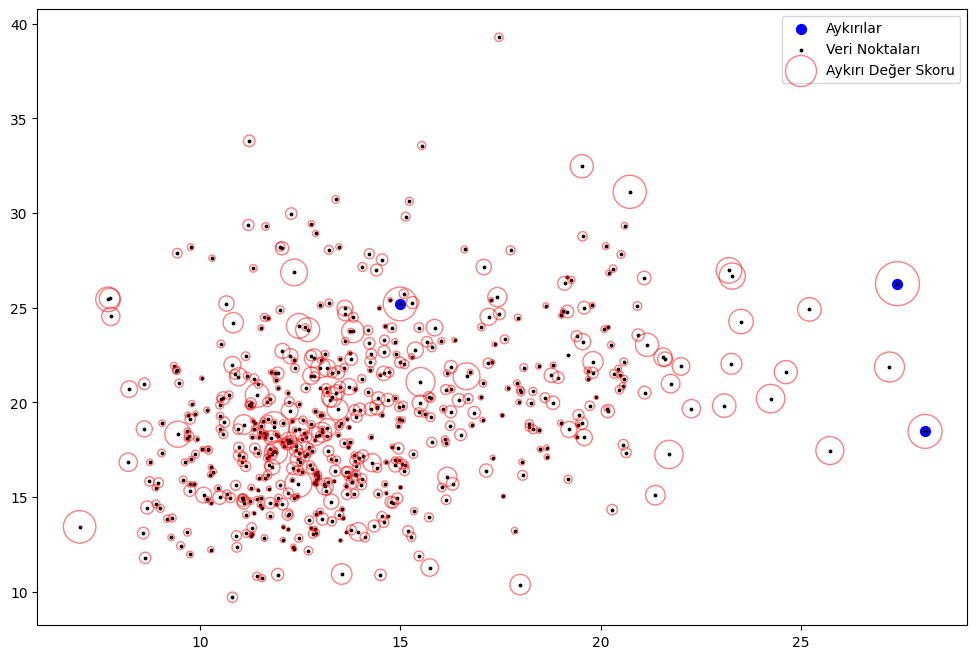

In [111]:
# yerel aykırı faktör yöntemi ile belirlenen aykırı değerleri çıkaralım
plt.figure(figsize=(12,8))
plt.scatter(x.iloc[outlier_index, 0], x.iloc[outlier_index, 1], color="blue", s=50, label="Aykırılar")
plt.scatter(x.iloc[:,0], x.iloc[:,1], color="k", s=3, label="Veri Noktaları")
radius = (X_score.max() - X_score) / (X_score.max() - X_score.min())
outlier_score["radius"] = radius
plt.scatter(x.iloc[:,0], x.iloc[:,1], s=1000*radius, edgecolors="r", alpha=0.5, facecolors="none", label="Aykırı Değer Skoru")
plt.legend()
plt.show()


In [112]:
# aykırı değerleri çıkaralım
x = x.drop(outlier_index)
y = y.drop(outlier_index).values

In [113]:
# eğitim test bölünmesi
X_egitim, X_test, Y_egitim, Y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [114]:
# standardizasyon
scaler = StandardScaler()
X_egitim = scaler.fit_transform(X_egitim)
X_test = scaler.transform(X_test)

In [115]:
# görselleştirmede kullanmak için veri çerçevesi oluşturalım
X_egitim_df = pd.DataFrame(X_egitim, columns=columns)
X_egitim_df_describe = X_egitim_df.describe()
X_egitim_df["hedef"] = Y_egitim

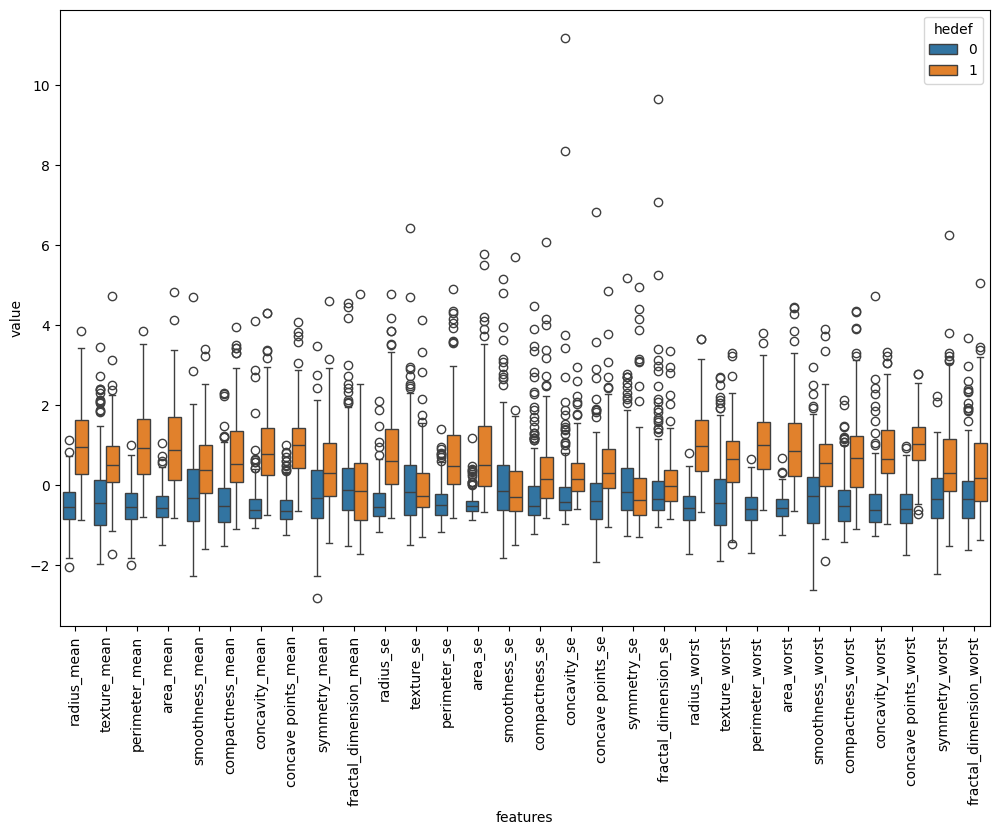

In [134]:
# kutu grafiği 
data_melted = pd.melt(X_egitim_df, id_vars="hedef", var_name="features", value_name="value")
plt.figure(figsize=(12,8))
sns.boxplot(x = "features", y= "value", hue="hedef", data=data_melted)
plt.xticks(rotation=90)
plt.show()

K-En Yakın Komşu
-Sınıflandırıcı olarak K En yakın komşu algoritmasını kullanalım
-En uygun K değerini bulalım

In [135]:
# k en yakın komşu sınıflandırması
# model
knn = KNeighborsClassifier(n_neighbors=2)

# eğitim
knn.fit(X_egitim, Y_egitim)

,n_neighbors,2
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [ ]:
# tahmin
y_pred = knn.predict(X_test)

Karışıklık Matrisi:  [[102   0]
 [ 11  57]]


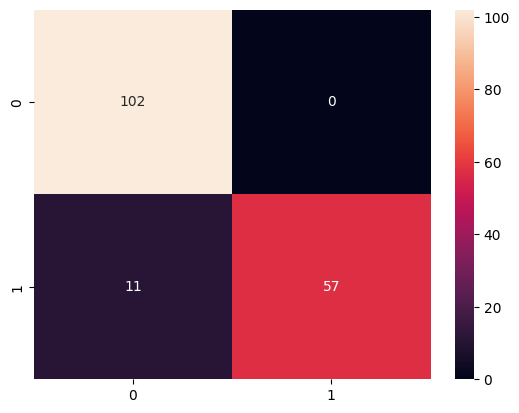

In [137]:
# karışıklık matrisi
cm = confusion_matrix(Y_test, y_pred)
print("Karışıklık Matrisi: ", cm)
sns.heatmap(cm, annot=True, fmt=".0f")
plt.show()

In [138]:
# doğruluk 
dogruluk = accuracy_score(Y_test, y_pred)
print("Doğruluk: ", dogruluk)

Doğruluk:  0.9352941176470588


In [140]:
from sklearn.model_selection import GridSearchCV
# en iyi k değeri
def enİyiParametreler(x_egitim, x_test, y_egitim, y_test):
    # k değeri
    k_range = list(range(1,31))

    # "uniform": tek tip ağırlıklar tüm noktalar eşit olarak ağırlıklandırılır
    # "distance": mesafelerinin tersine göre ağırlık noktaları bu durumda
    weight_options = ["uniform", "distance"]  # farklı knn parametreleri

    # ızgara araması için parametreleri bir sözlük içerisine ekleyelim
    param_grid = dict(n_neighbors = k_range, weights=weight_options)

    # knn sınıflandırıcısı
    knn = KNeighborsClassifier()
    # çapraz doğrulama ile ızgara arama
    grid = GridSearchCV(knn, param_grid, cv=10, scoring="accuracy")
    # eğitim 
    grid.fit(x_egitim, y_egitim)

    # en iyi sonucu verern parametrelerin gösterimi
    print(f"En iyi eğitim skoru: {grid.best_params_}")
    print()

    #  en iyi sonucu veren parametreler ile yeni bir k en yakın komşu modeli 
    knn = KNeighborsClassifier(**grid.best_params_)
    # eğitim 
    knn.fit(x_egitim, y_egitim)

    # tahminleme
    y_pred_test = knn.predict(x_test)
    y_pred_train = knn.predict(x_egitim)

    # karışıklık matrisi 
    cm_test = confusion_matrix(y_test, y_pred_test)
    cm_train =confusion_matrix(y_egitim, y_pred_train)

    # doğruluk ve sonuçların yazdırılması
    acc_test = accuracy_score(y_test, y_pred_test)
    acc_train = accuracy_score(y_egitim, y_pred_train)
    print(f"Test doğruluğu: {acc_test}\nEğitim doğruluğu: {acc_train}")
    print()
    print("Karışıklık Matrisi Test: ")
    print(cm_test)
    print("Karışıklık Matrisi Eğitim: ")
    print(cm_train)

    return grid
    

In [141]:
# en iyi k değeri ile oluşturulan model
grid = enİyiParametreler(X_egitim, X_test, Y_egitim, Y_test)

En iyi eğitim skoru: {'n_neighbors': 4, 'weights': 'distance'}

Test doğruluğu: 0.9470588235294117
Eğitim doğruluğu: 1.0

Karışıklık Matrisi Test: 
[[100   2]
 [  7  61]]
Karışıklık Matrisi Eğitim: 
[[255   0]
 [  0 141]]


Temel Bileşen Analizi
-- Verimizi 2 temel bileşene düşürerek sınıflandırma yapacağız

In [142]:
# standardizasyon
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [147]:
# temel bileşeni tanımla, 2 tane bileşenden oluşsun
pca = PCA(n_components=2)

In [144]:
pca.fit(x_scaled)

,n_components,2
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [ ]:
# pca uygula
X_reduced_pca = pca.transform(x_scaled)

In [150]:
x.shape

(566, 30)

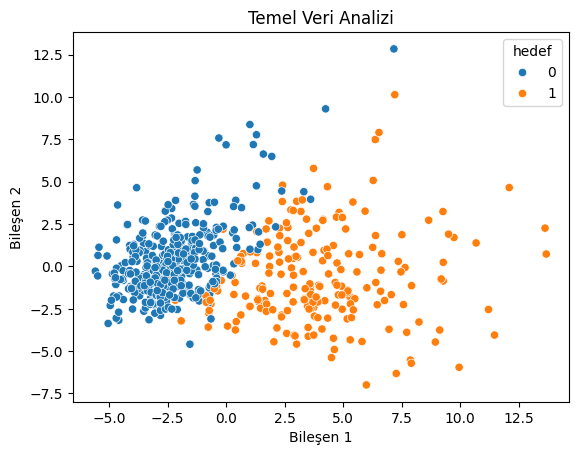

In [146]:
# pca'i yorumlamak için veri çerçevesine alalım
pca_data = pd.DataFrame(X_reduced_pca, columns=["p1", "p2"])
pca_data["hedef"] = y
plt.figure()
sns.scatterplot(x="p1", y="p2", hue="hedef", data=pca_data)
plt.title("Temel Veri Analizi")
plt.xlabel("Bileşen 1")
plt.ylabel("Bileşen 2")
plt.show()

In [155]:
# pca sonucu elde edilen verinin eğitim ve test bölünmesi
X_train_pca, X_test_pca, Y_train_pca, Y_test_pca = train_test_split(X_reduced_pca, y, test_size=0.3, random_state=42)

In [156]:
# pca sonucu elde edilen veri için en iyi knn değerlerinin bulunması
grid_pca = enİyiParametreler(X_train_pca, X_test_pca, Y_train_pca, Y_test_pca)

En iyi eğitim skoru: {'n_neighbors': 7, 'weights': 'uniform'}

Test doğruluğu: 0.9294117647058824
Eğitim doğruluğu: 0.9545454545454546

Karışıklık Matrisi Test: 
[[97  5]
 [ 7 61]]
Karışıklık Matrisi Eğitim: 
[[247   8]
 [ 10 131]]


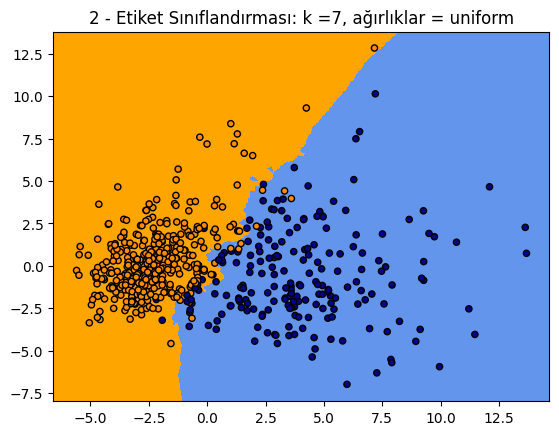

In [157]:
# pca sonucu elde edilen verinin tahminlemesi ve görselleştirilmesi
cmap_light = ListedColormap(["orange", "cornflowerblue"])
cmap_bold = ListedColormap(["darkorange", "darkblue"])

h = 0.05 # mesh boyutu
X = X_reduced_pca
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

Z = grid_pca.predict(np.c_[xx.ravel(), yy.ravel()])

Z = Z.reshape(xx.shape)
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

# eğitimde kullanılan her bir noktayı görselleştirelim
plt.scatter(X[:,0], X[:,1], c=y, cmap=cmap_bold, edgecolors="k", s=20)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title(f"{2} - Etiket Sınıflandırması: k ={grid_pca.best_estimator_.n_neighbors}, ağırlıklar = {grid_pca.best_estimator_.weights}")
plt.show()


Komşuluk Bileşenleri Analizi

-- Komşuluk bileşenleri analizi, çok değişkenli verilerin veriler üzerinde belirli bir mesafe ölçüsüne göre farklı sınıflarda sınıflandırılması için denetimli bir öğrenme yöntemidir.

In [158]:
# komşuluk bileşeni tanımla, 2 tane bileşenden oluşsun
nca = NeighborhoodComponentsAnalysis(n_components=2, random_state= 42)

In [159]:
# komşuluk eğitimi 
nca.fit(x_scaled, y)

,n_components,2
,init,'auto'
,warm_start,False
,max_iter,50
,tol,1e-05
,callback,None
,verbose,0
,random_state,42


In [165]:
# komşuluk uygula
X_reduced_nca = nca.transform(x_scaled)
X_reduced_nca.shape

(566, 2)

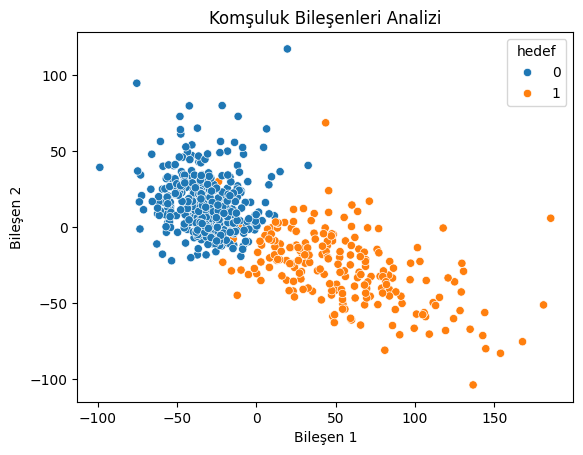

In [166]:
# komşuluğu yorumlamak için veri çerçevesine alalım
nca_data = pd.DataFrame(X_reduced_nca, columns= ["p1", "p2"])
nca_data["hedef"] = y
sns.scatterplot(x="p1", y="p2", hue="hedef", data=nca_data)
plt.title("Komşuluk Bileşenleri Analizi")
plt.xlabel("Bileşen 1")
plt.ylabel("Bileşen 2")
plt.show()

In [167]:
# nca sonucu elde edilen verinin eğitim ve test bölünmesi
X_train_nca, X_test_nca, Y_train_nca, Y_test_nca = train_test_split(X_reduced_nca, y, test_size=0.3, random_state=42)

In [168]:
# nca sonucu elde edilen veri için en iyi knn değerlerinin bulunması
grid_nca = enİyiParametreler(X_train_nca, X_test_nca, Y_train_nca, Y_test_nca)

En iyi eğitim skoru: {'n_neighbors': 1, 'weights': 'uniform'}

Test doğruluğu: 0.9764705882352941
Eğitim doğruluğu: 1.0

Karışıklık Matrisi Test: 
[[101   1]
 [  3  65]]
Karışıklık Matrisi Eğitim: 
[[255   0]
 [  0 141]]


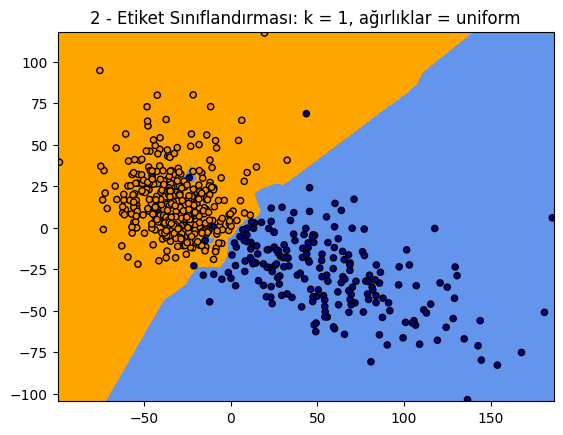

In [169]:
# nca sonucu elde edilen verinin tahminlemesi ve görselleştirilmesi
cmap_light = ListedColormap(["orange", "cornflowerblue"])
cmap_bold = ListedColormap(["darkorange", "darkblue"])

h = 0.2
X = X_reduced_nca
x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

Z = grid_nca.predict(np.c_[xx.ravel(), yy.ravel()])

Z = Z.reshape(xx.shape)
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

# eğitimde kullanılan her bir noktayı görselleştirelim
plt.scatter(X[:,0], X[:,1], c=y, cmap=cmap_bold, edgecolors="k", s=20)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title(f"{2} - Etiket Sınıflandırması: k = {grid_nca.best_estimator_.n_neighbors}, ağırlıklar = {grid_nca.best_estimator_.weights}")
plt.show()